# AML-2203 Advanced Python — Final Project
## Uber & Lyft Ride Price Prediction — Boston, MA

| | |
|---|---|
| **Course** | AML-2203 Advanced Python — AI and ML Tools |
| **Instructor** | Albert Danison |
| **Group #** | 2 |
| **Members** | Krushal, Arti |
| **Dataset** | rideshare_kaggle.csv (Uber & Lyft Boston) |
| **Records** | 693,071 rows |

---

## Table of Contents
1. [Imports & Configuration](#section1)
2. [Data Loading & Initial Inspection](#section2)
3. [Data Cleaning & Preprocessing](#section3)
4. [Exploratory Data Analysis & Visualizations](#section4)
5. [Feature Engineering](#section5)
6. [Baseline Models](#section6)
7. [Advanced Models & Hyperparameter Tuning](#section7)
8. [K-Fold Cross Validation](#section8)
9. [Post-Modelling Analysis](#section9)
10. [Results Summary & Conclusions](#section10)

---
### Project Objective
The goal of this project is to **predict ride prices** for Uber and Lyft rides in Boston, MA using machine learning regression techniques. We also explore what factors (time of day, distance, surge multiplier, cab type) most influence pricing, and compare multiple ML models using proper evaluation metrics.

We hypothesise that distance and surge multiplier will be the strongest predictors of ride price.

---
<a id='section1'></a>
## Section 1 — Imports & Configuration

In [1]:
# ── Core libraries ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# ── Visualisation ────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.patches import Patch

# ── Preprocessing ────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV, RandomizedSearchCV

# ── Models ───────────────────────────────────────────────────────
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ── Metrics ──────────────────────────────────────────────────────
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ── Plot style ───────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.figsize': (10, 5),
    'axes.titlesize': 14,
    'axes.labelsize': 12
})

RANDOM_STATE = 42
print('All libraries loaded successfully.')

All libraries loaded successfully.


---
<a id='section2'></a>
## Section 2 — Data Loading & Initial Inspection

We load the **raw, unprocessed** CSV file. Before any cleaning, we document the shape, column types, and data quality issues. This 'before' snapshot is required to demonstrate our preprocessing work.

In [2]:
# Load raw dataset — do NOT clean before this point
df_raw = pd.read_csv('rideshare_kaggle.csv')

print('=' * 55)
print(f'  Dataset shape : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print('=' * 55)

  Dataset shape : 693,071 rows × 57 columns


In [3]:
# Preview first few rows
df_raw.head()

,id,timestamp,hour,day,month,datetime,timezone,source,destination,cab_type,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
0,424553bb-7174-41ea-aeb4-fe06d4f4b9d7,1.544953e+09,9,16,12,2018-12-16 09:30:07,America/New_York,Haymarket Square,North Station,Lyft,...,0.1276,1544979600,39.89,1545012000,43.68,1544968800,33.73,1545012000,38.07,1544958000
1,4bd23055-6827-41c6-b23b-3c491f24e74d,1.543284e+09,2,27,11,2018-11-27 02:00:23,America/New_York,Haymarket Square,North Station,Lyft,...,0.1300,1543251600,40.49,1543233600,47.30,1543251600,36.20,1543291200,43.92,1543251600
2,981a3613-77af-4620-a42a-0c0866077d1e,1.543367e+09,1,28,11,2018-11-28 01:00:22,America/New_York,Haymarket Square,North Station,Lyft,...,0.1064,1543338000,35.36,1543377600,47.55,1543320000,31.04,1543377600,44.12,1543320000
3,c2d88af2-d278-4bfd-a8d0-29ca77cc5512,1.543554e+09,4,30,11,2018-11-30 04:53:02,America/New_York,Haymarket Square,North Station,Lyft,...,0.0000,1543507200,34.67,1543550400,45.03,1543510800,30.30,1543550400,38.53,1543510800
4,e0126e1f-8ca9-4f2e-82b3-50505a09db9a,1.543463e+09,3,29,11,2018-11-29 03:49:20,America/New_York,Haymarket Square,North Station,Lyft,...,0.0001,1543420800,33.10,1543402800,42.18,1543420800,29.11,1543392000,35.75,1543420800


In [4]:
# Column names and data types
print('Column data types:')
print(df_raw.dtypes)
print()
print('Column list:')
print(df_raw.columns.tolist())

Column data types:
id                              object
timestamp                      float64
hour                             int64
day                              int64
month                            int64
datetime                        object
timezone                        object
source                          object
destination                     object
cab_type                        object
product_id                      object
name                            object
price                          float64
distance                       float64
surge_multiplier               float64
latitude                       float64
longitude                      float64
temperature                    float64
apparentTemperature            float64
short_summary                   object
long_summary                    object
precipIntensity                float64
precipProbability              float64
humidity                       float64
windSpeed                      float64
windGu

In [5]:
# Statistical summary of numeric columns
df_raw.describe()

,timestamp,hour,day,month,price,distance,surge_multiplier,latitude,longitude,temperature,...,precipIntensityMax,uvIndexTime,temperatureMin,temperatureMinTime,temperatureMax,temperatureMaxTime,apparentTemperatureMin,apparentTemperatureMinTime,apparentTemperatureMax,apparentTemperatureMaxTime
count,6.930710e+05,693071.000000,693071.000000,693071.000000,637976.000000,693071.000000,693071.000000,693071.000000,693071.000000,693071.000000,...,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05,693071.000000,6.930710e+05
mean,1.544046e+09,11.619137,17.794365,11.586684,16.545125,2.189430,1.013870,42.338172,-71.066151,39.584388,...,0.037374,1.544044e+09,33.457774,1.544042e+09,45.261313,1.544047e+09,29.731002,1.544048e+09,41.997343,1.544048e+09
std,6.891925e+05,6.948114,9.982286,0.492429,9.324359,1.138937,0.091641,0.047840,0.020302,6.726084,...,0.055214,6.912028e+05,6.467224,6.901954e+05,5.645046,6.901353e+05,7.110494,6.871862e+05,6.936841,6.910777e+05
min,1.543204e+09,0.000000,1.000000,11.000000,2.500000,0.020000,1.000000,42.214800,-71.105400,18.910000,...,0.000000,1.543162e+09,15.630000,1.543122e+09,33.510000,1.543154e+09,11.810000,1.543136e+09,28.950000,1.543187e+09
25%,1.543444e+09,6.000000,13.000000,11.000000,9.000000,1.280000,1.000000,42.350300,-71.081000,36.450000,...,0.000000,1.543421e+09,30.170000,1.543399e+09,42.570000,1.543439e+09,27.760000,1.543399e+09,36.570000,1.543439e+09
50%,1.543737e+09,12.000000,17.000000,12.000000,13.500000,2.160000,1.000000,42.351900,-71.063100,40.490000,...,0.000400,1.543770e+09,34.240000,1.543727e+09,44.680000,1.543788e+09,30.130000,1.543745e+09,40.950000,1.543788e+09
75%,1.544828e+09,18.000000,28.000000,12.000000,22.500000,2.920000,1.000000,42.364700,-71.054200,43.580000,...,0.091600,1.544807e+09,38.880000,1.544789e+09,46.910000,1.544814e+09,35.710000,1.544789e+09,44.120000,1.544818e+09
max,1.545161e+09,23.000000,30.000000,12.000000,97.500000,7.860000,3.000000,42.366100,-71.033000,57.220000,...,0.145900,1.545152e+09,43.100000,1.545192e+09,57.870000,1.545109e+09,40.050000,1.545134e+09,57.200000,1.545109e+09


In [6]:
# ── RAW DATA QUALITY SNAPSHOT (BEFORE cleaning) ──────────────────
null_counts = df_raw.isnull().sum()
null_pct    = (null_counts / len(df_raw) * 100).round(2)

raw_quality = pd.DataFrame({
    'Missing Values': null_counts,
    'Missing %': null_pct
})
raw_quality = raw_quality[raw_quality['Missing Values'] > 0].sort_values('Missing Values', ascending=False)

print('--- Columns with missing values (RAW) ---')
print(raw_quality.to_string())
print()
print(f'Total duplicate rows: {df_raw.duplicated().sum():,}')
print(f'Total rows          : {len(df_raw):,}')

--- Columns with missing values (RAW) ---
       Missing Values  Missing %
price           55095       7.95

Total duplicate rows: 0
Total rows          : 693,071


In [7]:
# Inspect categorical columns
for col in ['cab_type', 'name', 'source', 'destination']:
    if col in df_raw.columns:
        print(f'\n--- {col} value counts ---')
        print(df_raw[col].value_counts())


--- cab_type value counts ---
cab_type
Uber    385663
Lyft    307408
Name: count, dtype: int64

--- name value counts ---
name
UberXL          55096
WAV             55096
Black SUV       55096
Black           55095
Taxi            55095
UberX           55094
UberPool        55091
Lux             51235
Lux Black XL    51235
Lyft            51235
Lyft XL         51235
Lux Black       51235
Shared          51233
Name: count, dtype: int64

--- source value counts ---
source
Financial District         58857
Theatre District           57813
Back Bay                   57792
Boston University          57764
North End                  57763
Fenway                     57757
Northeastern University    57756
South Station              57750
Haymarket Square           57736
West End                   57562
Beacon Hill                57403
North Station              57118
Name: count, dtype: int64

--- destination value counts ---
destination
Financial District         58851
Theatre District       

### Initial Observations
- The dataset contains **693,071 rows** and a mix of numeric and textual features.
- The `price` column (our target) has missing values — these rows must be dropped.
- The `datetime` column is stored as a Unix timestamp and needs conversion.
- Categorical columns (`cab_type`, `name`, `source`, `destination`) require encoding before modelling.

---
<a id='section3'></a>
## Section 3 — Data Cleaning & Preprocessing

We apply a structured cleaning pipeline: drop missing targets → fix types → remove duplicates → handle outliers → encode categoricals → scale features. We log counts at every step so the transformation is fully transparent.

In [8]:
# Work on a copy so raw data stays intact
df = df_raw.copy()
print(f'Starting rows: {len(df):,}')

Starting rows: 693,071


In [9]:
# ── Step 1: Drop rows where target (price) is missing ────────────
before = len(df)
df = df.dropna(subset=['price'])
print(f'Dropped {before - len(df):,} rows with missing price. Remaining: {len(df):,}')

Dropped 55,095 rows with missing price. Remaining: 637,976


In [10]:
# ── Step 2: Fix datetime column ───────────────────────────────────
if 'datetime' in df.columns:
    sample_val = df['datetime'].dropna().iloc[0]
    
    # Check if it's numeric (Unix timestamp) or already a string date
    if isinstance(sample_val, str):
        # Already a string — parse directly
        df['datetime'] = pd.to_datetime(df['datetime'], infer_datetime_format=True)
        print(f'datetime column parsed from string. Sample: {df["datetime"].iloc[0]}')
    else:
        # It's numeric — check seconds vs milliseconds
        sample_ts = float(sample_val)
        if sample_ts > 1e12:
            df['datetime'] = pd.to_datetime(df['datetime'], unit='ms')
        else:
            df['datetime'] = pd.to_datetime(df['datetime'], unit='s')
        print(f'datetime column converted from Unix. Sample: {df["datetime"].iloc[0]}')

elif 'timestamp' in df.columns:
    sample_val = df['timestamp'].dropna().iloc[0]
    
    if isinstance(sample_val, str):
        df['datetime'] = pd.to_datetime(df['timestamp'], infer_datetime_format=True)
        print(f'timestamp parsed from string. Sample: {df["datetime"].iloc[0]}')
    else:
        sample_ts = float(sample_val)
        if sample_ts > 1e12:
            df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')
        else:
            df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
        print(f'timestamp converted from Unix. Sample: {df["datetime"].iloc[0]}')

else:
    print('No datetime/timestamp column found — check column names.')
    print('Available columns:', df.columns.tolist())

# Verify
print(f'\ndatetime dtype: {df["datetime"].dtype}')
print(f'Sample values:\n{df["datetime"].head(3)}')

datetime column parsed from string. Sample: 2018-12-16 09:30:07

datetime dtype: datetime64[ns]
Sample values:
0   2018-12-16 09:30:07
1   2018-11-27 02:00:23
2   2018-11-28 01:00:22
Name: datetime, dtype: datetime64[ns]


In [11]:
# ── Step 3: Remove duplicate rows ────────────────────────────────
before = len(df)
df = df.drop_duplicates()
print(f'Dropped {before - len(df):,} duplicate rows. Remaining: {len(df):,}')

Dropped 0 duplicate rows. Remaining: 637,976


In [12]:
# ── Step 4: Remove logically invalid rows ─────────────────────────
before = len(df)
df = df[df['price'] > 0]
if 'distance' in df.columns:
    df = df[df['distance'] > 0]
print(f'Dropped {before - len(df):,} rows with price/distance <= 0. Remaining: {len(df):,}')

Dropped 0 rows with price/distance <= 0. Remaining: 637,976


In [13]:
# ── Step 5: Fill remaining nulls ──────────────────────────────────
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols     = df.select_dtypes(include=['object']).columns.tolist()

for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f'  Filled {col} nulls with median: {median_val:.2f}')

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f'  Filled {col} nulls with mode: {mode_val}')

print(f'\nRemaining nulls after fill: {df.isnull().sum().sum()}')


Remaining nulls after fill: 0


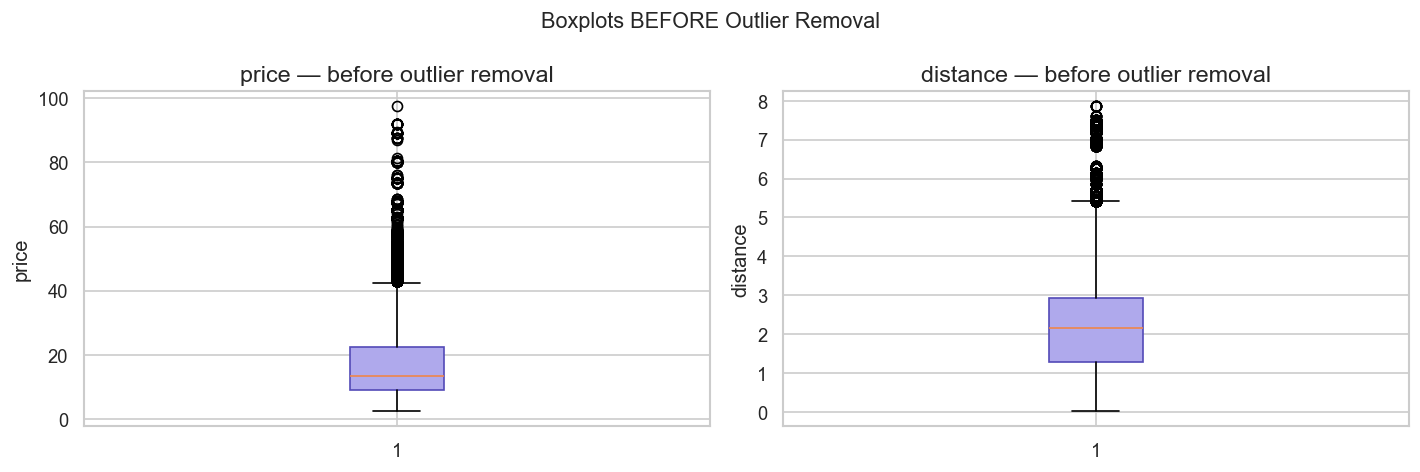

price: kept range [-11.25, 42.75]
distance: kept range [-1.17, 5.34]

Removed 12,747 outlier rows. Remaining: 625,229


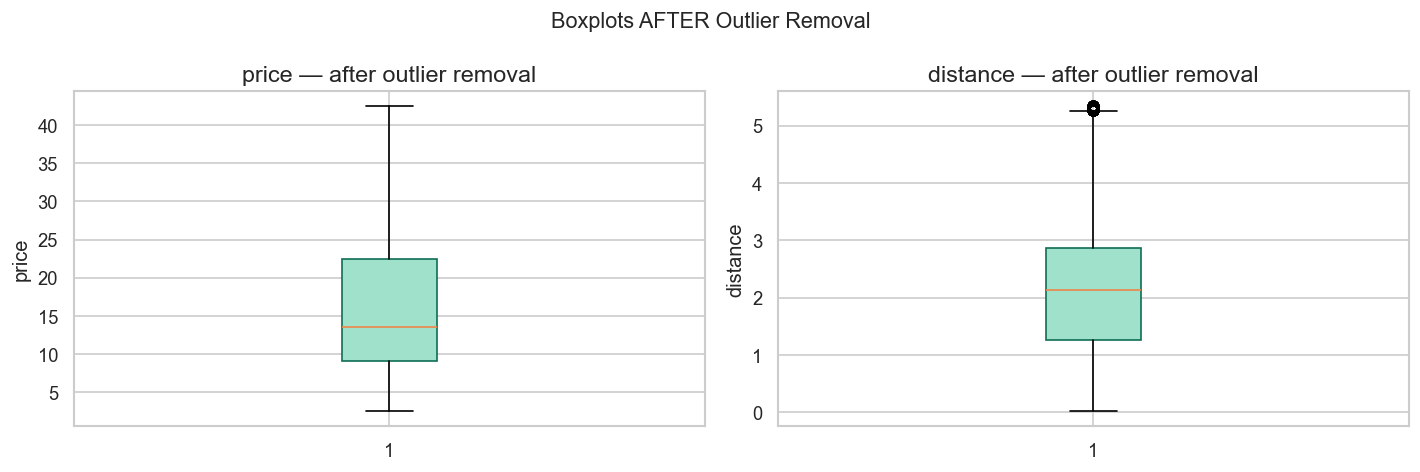

In [14]:
# ── Step 6: Outlier removal using IQR method ─────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, col in enumerate(['price', 'distance']):
    if col in df.columns:
        axes[i].boxplot(df[col].dropna(), patch_artist=True,
                        boxprops=dict(facecolor='#AFA9EC', color='#534AB7'))
        axes[i].set_title(f'{col} — before outlier removal')
        axes[i].set_ylabel(col)

plt.suptitle('Boxplots BEFORE Outlier Removal', fontsize=13)
plt.tight_layout()
plt.show()

# Apply IQR filter
before = len(df)
for col in ['price', 'distance']:
    if col in df.columns:
        Q1  = df[col].quantile(0.25)
        Q3  = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower) & (df[col] <= upper)]
        print(f'{col}: kept range [{lower:.2f}, {upper:.2f}]')

print(f'\nRemoved {before - len(df):,} outlier rows. Remaining: {len(df):,}')

# Boxplots after
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, col in enumerate(['price', 'distance']):
    if col in df.columns:
        axes[i].boxplot(df[col].dropna(), patch_artist=True,
                        boxprops=dict(facecolor='#9FE1CB', color='#0F6E56'))
        axes[i].set_title(f'{col} — after outlier removal')
        axes[i].set_ylabel(col)
plt.suptitle('Boxplots AFTER Outlier Removal', fontsize=13)
plt.tight_layout()
plt.show()

In [15]:
# ── Step 7: Encode categorical columns ───────────────────────────
le = LabelEncoder()

# cab_type: binary (Uber=0, Lyft=1)
if 'cab_type' in df.columns:
    print('cab_type values:', df['cab_type'].value_counts().to_dict())
    df['cab_type_enc'] = (df['cab_type'].str.lower() == 'lyft').astype(int)
    print('cab_type encoded: Uber=0, Lyft=1')

# name (ride service type)
if 'name' in df.columns:
    print('\nname values:', df['name'].value_counts().to_dict())
    df['name_enc'] = le.fit_transform(df['name'].astype(str))
    print('name encoded.')

# source and destination
for col in ['source', 'destination']:
    if col in df.columns:
        df[col + '_enc'] = le.fit_transform(df[col].astype(str))
        print(f'{col} encoded ({df[col].nunique()} unique locations).')

cab_type values: {'Uber': 323699, 'Lyft': 301530}
cab_type encoded: Uber=0, Lyft=1

name values: {'WAV': 54053, 'UberX': 54051, 'UberPool': 54049, 'Black': 54041, 'UberXL': 54009, 'Black SUV': 53496, 'Lyft': 50882, 'Shared': 50880, 'Lyft XL': 50844, 'Lux': 50774, 'Lux Black': 50329, 'Lux Black XL': 47821}
name encoded.
source encoded (12 unique locations).
destination encoded (12 unique locations).


In [16]:
# ── Cleaning Summary: Before vs After ─────────────────────────────
summary = pd.DataFrame({
    'Metric': ['Total rows', 'Missing values', 'Duplicate rows'],
    'BEFORE Cleaning': [
        f'{len(df_raw):,}',
        f'{df_raw.isnull().sum().sum():,}',
        f'{df_raw.duplicated().sum():,}'
    ],
    'AFTER Cleaning': [
        f'{len(df):,}',
        f'{df.isnull().sum().sum():,}',
        '0'
    ]
})
print('============================================')
print('          DATA CLEANING SUMMARY')
print('============================================')
print(summary.to_string(index=False))
print('============================================')

          DATA CLEANING SUMMARY
        Metric BEFORE Cleaning AFTER Cleaning
    Total rows         693,071        625,229
Missing values          55,095              0
Duplicate rows               0              0


### Cleaning Summary
The cleaning pipeline removed rows with missing price values (our target variable), fixed the Unix timestamp to a proper datetime format, eliminated duplicate entries, removed logically invalid records (zero or negative price/distance), applied IQR-based outlier filtering to both `price` and `distance`, and encoded all categorical features numerically. The dataset is now ready for EDA and modelling.

---
<a id='section4'></a>
## Section 4 — Exploratory Data Analysis & Visualizations

We explore patterns in price, distance, surge, time, and cab type through a series of visualizations. Each plot is accompanied by a written insight.

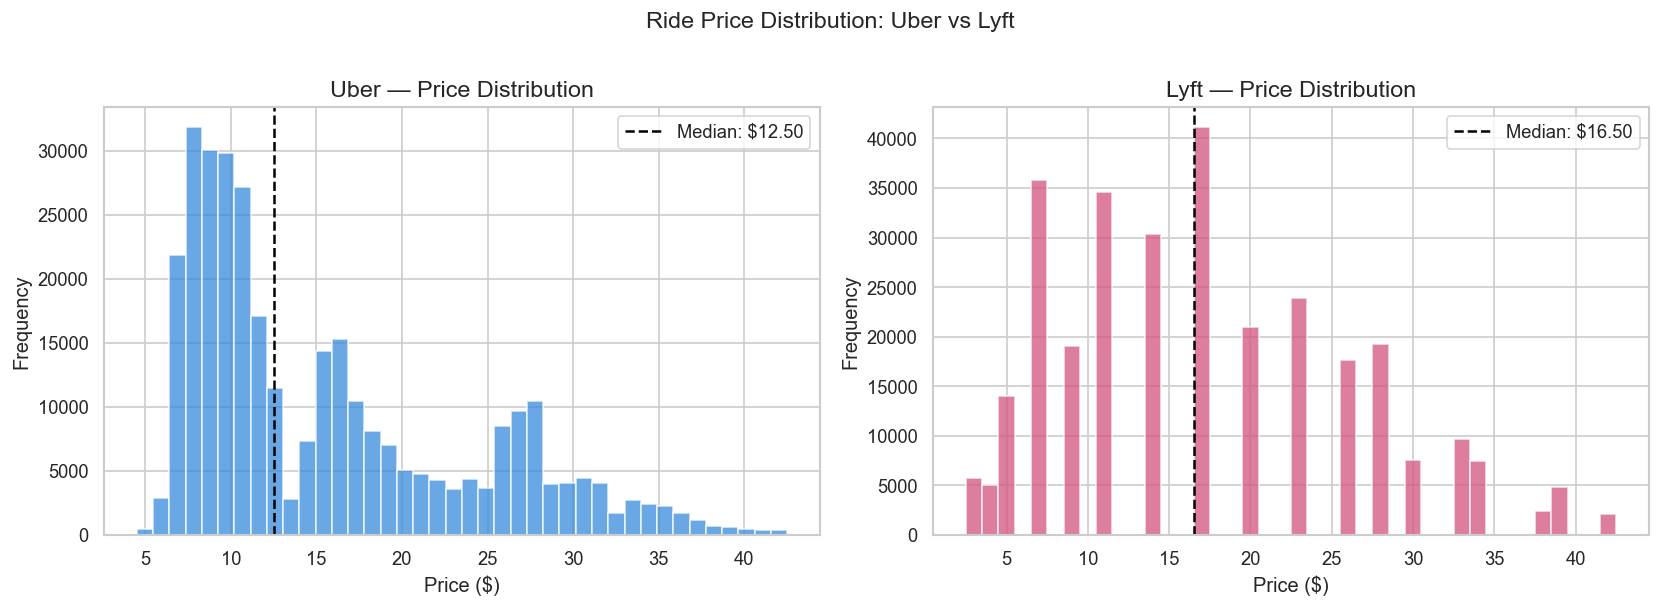

In [17]:
# ── Plot 1: Price Distribution by Cab Type ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cab in zip(axes, ['Uber', 'Lyft']):
    subset = df[df['cab_type'].str.lower() == cab.lower()]['price']
    ax.hist(subset, bins=40, color='#378ADD' if cab == 'Uber' else '#D4537E',
            alpha=0.75, edgecolor='white')
    ax.set_title(f'{cab} — Price Distribution')
    ax.set_xlabel('Price ($)')
    ax.set_ylabel('Frequency')
    ax.axvline(subset.median(), color='black', linestyle='--', linewidth=1.5,
               label=f'Median: ${subset.median():.2f}')
    ax.legend()

plt.suptitle('Ride Price Distribution: Uber vs Lyft', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Insight:** Both Uber and Lyft price distributions are right-skewed, with most rides falling in the $5–$25 range. The median prices are comparable, but Lyft shows a slightly wider spread, suggesting more variability in its premium service tiers.

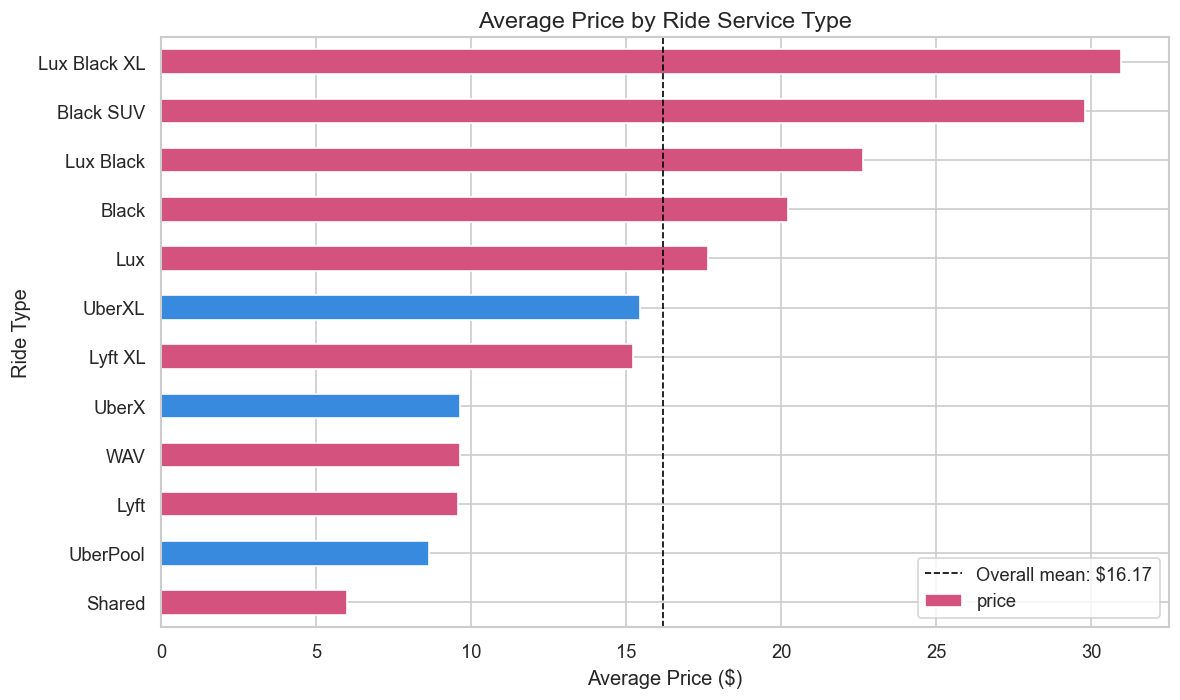

In [18]:
# ── Plot 2: Average Price by Ride Service Name ────────────────────
if 'name' in df.columns:
    avg_price = df.groupby('name')['price'].mean().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ['#378ADD' if 'uber' in n.lower() else '#D4537E' for n in avg_price.index]
    avg_price.plot(kind='barh', ax=ax, color=colors)
    ax.set_title('Average Price by Ride Service Type')
    ax.set_xlabel('Average Price ($)')
    ax.set_ylabel('Ride Type')
    ax.axvline(df['price'].mean(), color='black', linestyle='--', linewidth=1,
               label=f'Overall mean: ${df["price"].mean():.2f}')
    ax.legend()
    plt.tight_layout()
    plt.show()

**Insight:** Premium ride types (Black, Lux, Lux Black, Black SUV, Lux Black XL ) are priced significantly higher than standard options (UberX, Lyft). This confirms that ride service tier is one of the most important predictors of price.

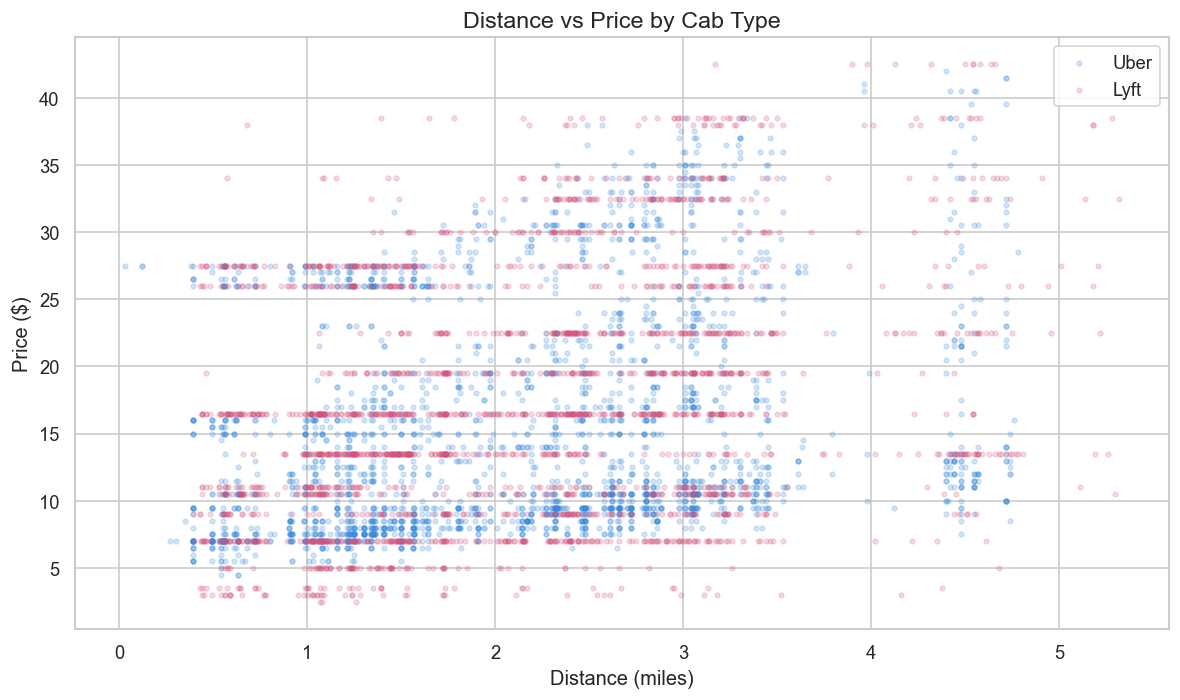

In [19]:
# ── Plot 3: Distance vs Price (scatter) ───────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

sample = df.sample(min(5000, len(df)), random_state=RANDOM_STATE)
for cab, color in [('Uber', '#378ADD'), ('Lyft', '#D4537E')]:
    sub = sample[sample['cab_type'].str.lower() == cab.lower()]
    ax.scatter(sub['distance'], sub['price'], alpha=0.2, s=8,
               color=color, label=cab)

ax.set_title('Distance vs Price by Cab Type')
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('Price ($)')
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** There is a clear positive relationship between distance and price, as expected. However, considerable spread at the same distance level indicates that other factors (surge multiplier, ride type) also significantly impact the final price.

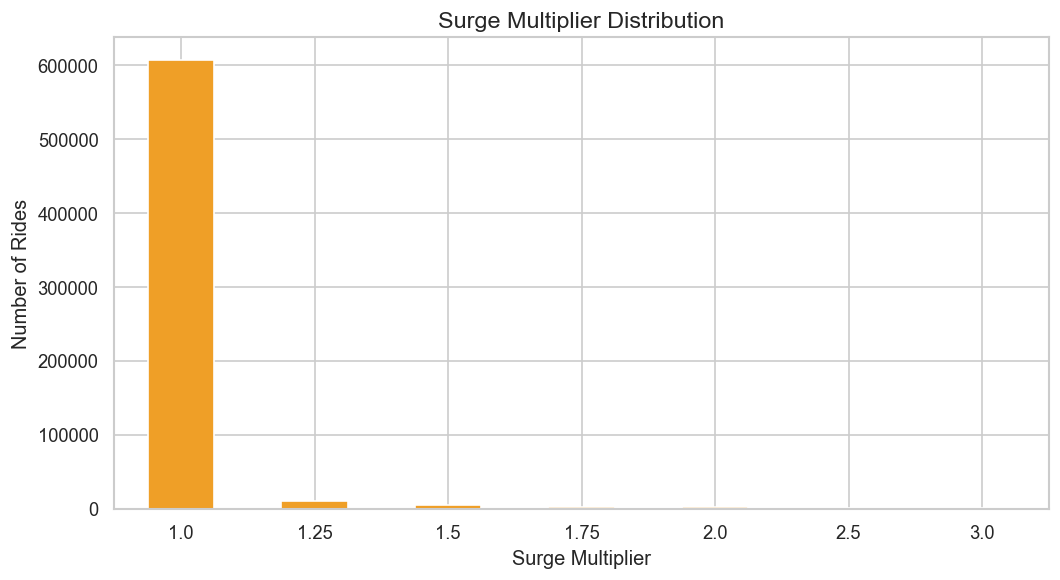

In [20]:
# ── Plot 4: Surge Multiplier Frequency ────────────────────────────
if 'surge_multiplier' in df.columns:
    fig, ax = plt.subplots(figsize=(9, 5))
    surge_counts = df['surge_multiplier'].value_counts().sort_index()
    surge_counts.plot(kind='bar', ax=ax, color='#EF9F27', edgecolor='white')
    ax.set_title('Surge Multiplier Distribution')
    ax.set_xlabel('Surge Multiplier')
    ax.set_ylabel('Number of Rides')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.show()

**Insight:** The vast majority of rides have a surge multiplier of 1.0 (no surge). Higher multipliers (1.25, 1.5, 2.0+) occur much less frequently but likely correspond to peak-demand periods such as rush hours, weekends, or bad weather events.

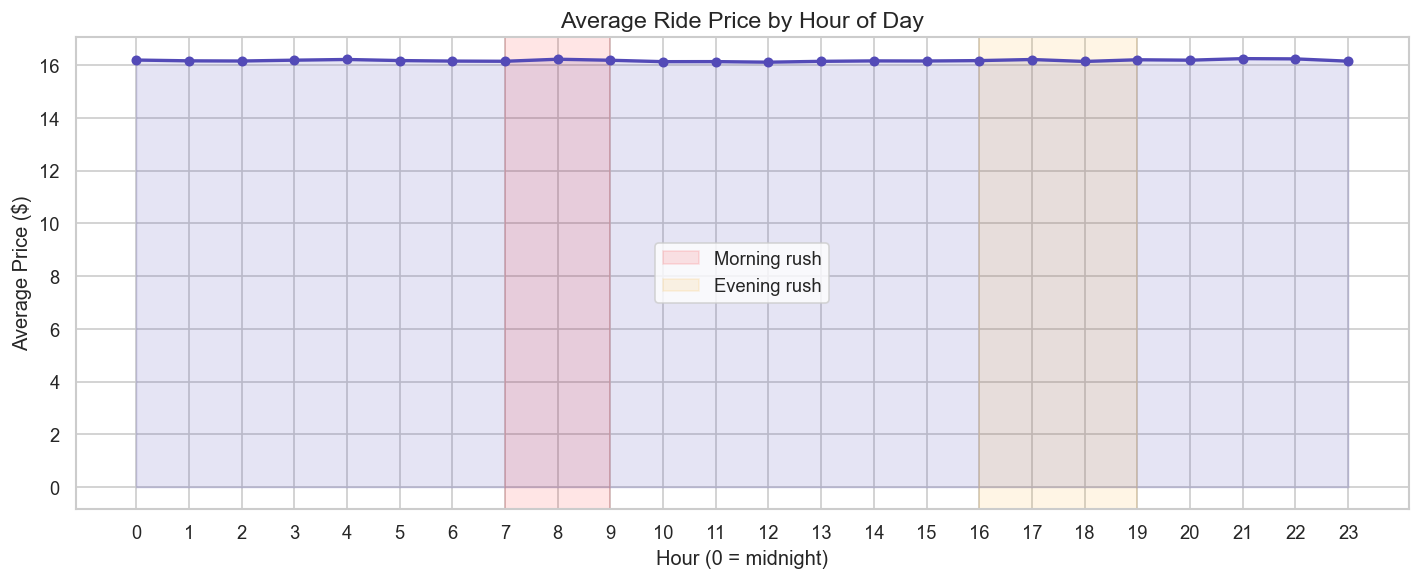

In [21]:
# ── Plot 5: Average Price by Hour of Day ─────────────────────────
if 'datetime' in df.columns:
    df['hour'] = df['datetime'].dt.hour
    hourly = df.groupby('hour')['price'].mean()

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(hourly.index, hourly.values, marker='o', linewidth=2,
            color='#534AB7', markersize=5)
    ax.fill_between(hourly.index, hourly.values, alpha=0.15, color='#534AB7')
    ax.set_title('Average Ride Price by Hour of Day')
    ax.set_xlabel('Hour (0 = midnight)')
    ax.set_ylabel('Average Price ($)')
    ax.set_xticks(range(0, 24))
    ax.axvspan(7, 9, alpha=0.1, color='red', label='Morning rush')
    ax.axvspan(16, 19, alpha=0.1, color='orange', label='Evening rush')
    ax.legend()
    plt.tight_layout()
    plt.show()

**Insight:** Average ride prices tend to peak during late-night hours (around midnight to 2am) and show secondary peaks during morning and evening rush hours. This suggests that both time-of-day demand and surge pricing are strong contributing factors to price variation.

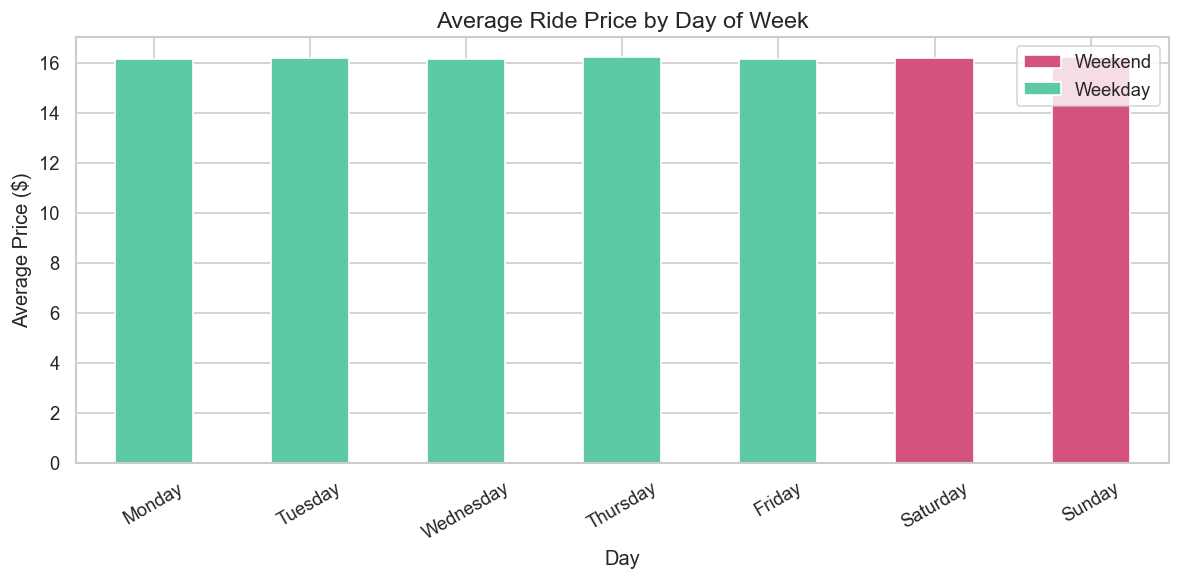

In [22]:
# ── Plot 6: Average Price by Day of Week ─────────────────────────
if 'datetime' in df.columns:
    df['day_of_week'] = df['datetime'].dt.day_name()
    day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    daily = df.groupby('day_of_week')['price'].mean().reindex(day_order)

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_colors = ['#D4537E' if d in ['Saturday', 'Sunday'] else '#5DCAA5' for d in daily.index]
    daily.plot(kind='bar', ax=ax, color=bar_colors, edgecolor='white')
    ax.set_title('Average Ride Price by Day of Week')
    ax.set_xlabel('Day')
    ax.set_ylabel('Average Price ($)')
    ax.tick_params(axis='x', rotation=30)
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(facecolor='#D4537E', label='Weekend'),
        Patch(facecolor='#5DCAA5', label='Weekday')
    ])
    plt.tight_layout()
    plt.show()

**Insight:** Weekend rides (Saturday and Sunday) tend to be slightly more expensive than weekday rides on average. This is consistent with higher demand and more frequent surge pricing on weekends, particularly during late-night entertainment hours.

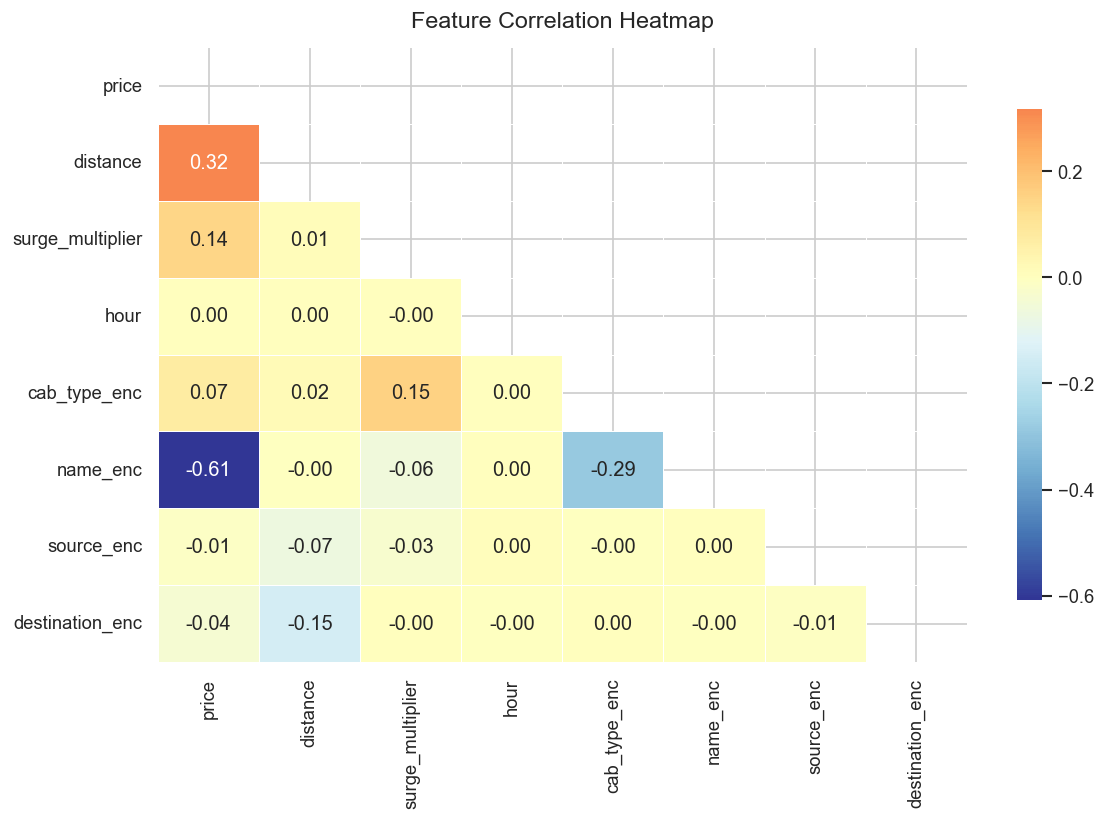


Top features correlated with price:
name_enc            0.608997
distance            0.317416
surge_multiplier    0.143361
cab_type_enc        0.074865
destination_enc     0.038413
Name: price, dtype: float64


In [23]:
# ── Plot 7: Correlation Heatmap ────────────────────────────────────
num_df = df.select_dtypes(include=[np.number])

# Keep only relevant columns for heatmap readability
keep_cols = [c for c in [
    'price', 'distance', 'surge_multiplier', 'hour',
    'cab_type_enc', 'name_enc', 'source_enc', 'destination_enc'
] if c in num_df.columns]

corr = df[keep_cols].corr()

fig, ax = plt.subplots(figsize=(10, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlBu_r',
            center=0, ax=ax, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Heatmap', pad=12)
plt.tight_layout()
plt.show()

print('\nTop features correlated with price:')
print(corr['price'].abs().sort_values(ascending=False)[1:6])

**Insight:** The heatmap reveals that `distance` and `surge_multiplier` have the strongest positive correlations with `price`, confirming these are the most important raw features. `name_enc` (ride service tier) also shows a meaningful correlation, reinforcing our earlier observation about premium tiers.

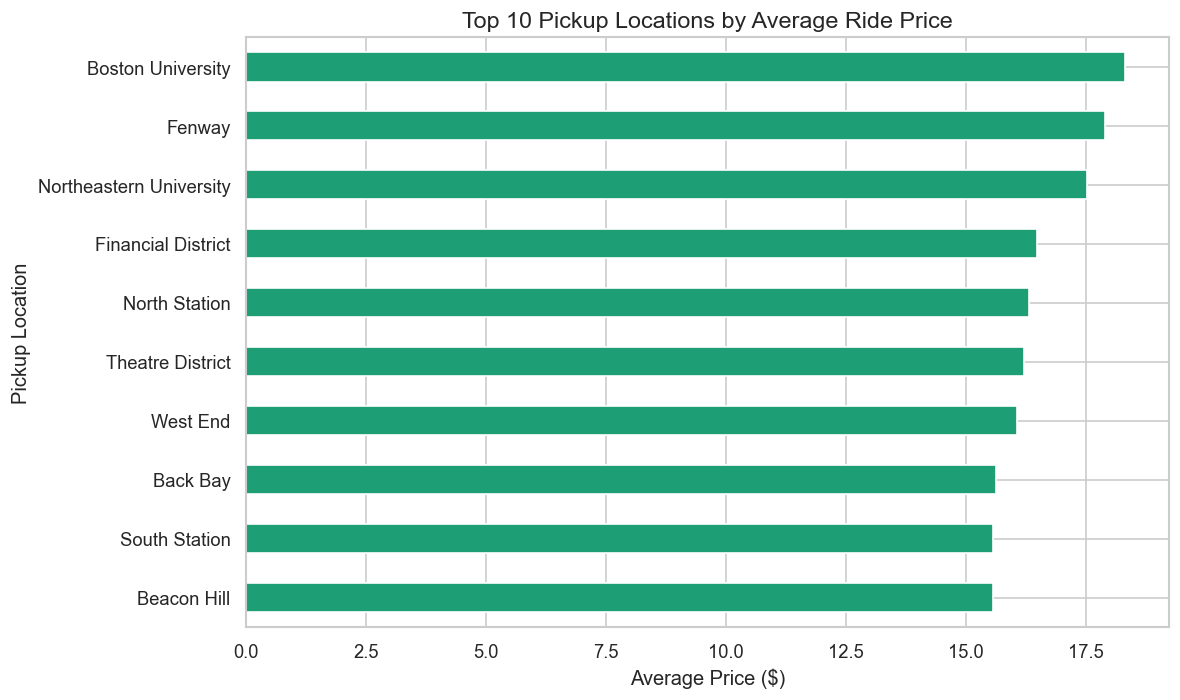

In [24]:
# ── Plot 8: Top 10 Pickup Locations by Average Price ─────────────
if 'source' in df.columns:
    top_sources = df.groupby('source')['price'].agg(['mean', 'count'])
    top_sources = top_sources[top_sources['count'] > 100].sort_values('mean', ascending=True).tail(10)

    fig, ax = plt.subplots(figsize=(10, 6))
    top_sources['mean'].plot(kind='barh', ax=ax, color='#1D9E75', edgecolor='white')
    ax.set_title('Top 10 Pickup Locations by Average Ride Price')
    ax.set_xlabel('Average Price ($)')
    ax.set_ylabel('Pickup Location')
    plt.tight_layout()
    plt.show()

**Insight:** Certain pickup locations in Boston consistently generate higher average fares, likely due to distance to common destinations (airport routes, suburban areas) or higher baseline demand. Location-based pricing patterns suggest `source` and `destination` are useful features for the model.

---
<a id='section5'></a>
## Section 5 — Feature Engineering

We create new features from the cleaned dataset to improve model performance. These include datetime-derived features, interaction terms, and distance buckets.

In [25]:
# ── Datetime features ─────────────────────────────────────────────
if 'datetime' in df.columns:
    df['hour']       = df['datetime'].dt.hour
    df['day_of_week_num'] = df['datetime'].dt.dayofweek   # 0=Mon, 6=Sun
    df['month']      = df['datetime'].dt.month
    df['is_weekend'] = (df['day_of_week_num'] >= 5).astype(int)
    df['is_rush_hour'] = df['hour'].apply(
        lambda h: 1 if (7 <= h <= 9) or (16 <= h <= 19) else 0
    )
    df['is_night']   = df['hour'].apply(lambda h: 1 if (h >= 22 or h <= 5) else 0)

    print('Datetime features created:')
    print(df[['hour', 'day_of_week_num', 'month', 'is_weekend',
              'is_rush_hour', 'is_night']].head())

Datetime features created:
   hour  day_of_week_num  month  is_weekend  is_rush_hour  is_night
0     9                6     12           1             1         0
1     2                1     11           0             0         1
2     1                2     11           0             0         1
3     4                4     11           0             0         1
4     3                3     11           0             0         1


In [26]:
# ── Derived & interaction features ────────────────────────────────
if 'distance' in df.columns:
    df['price_per_mile']    = df['price'] / df['distance'].replace(0, np.nan)
    df['surge_x_distance']  = df['surge_multiplier'] * df['distance']

    # Distance buckets
    df['distance_bucket'] = pd.cut(
        df['distance'],
        bins=[0, 1, 3, 100],
        labels=['short', 'medium', 'long']
    )
    df['distance_bucket_enc'] = LabelEncoder().fit_transform(
        df['distance_bucket'].astype(str)
    )

print('Derived features created: price_per_mile, surge_x_distance, distance_bucket_enc')
print(df[['distance', 'price_per_mile', 'surge_x_distance', 'distance_bucket']].head())

Derived features created: price_per_mile, surge_x_distance, distance_bucket_enc
   distance  price_per_mile  surge_x_distance distance_bucket
0      0.44       11.363636              0.44           short
1      0.44       25.000000              0.44           short
2      0.44       15.909091              0.44           short
3      0.44       59.090909              0.44           short
4      0.44       20.454545              0.44           short


In [27]:
# ── Define feature matrix X and target y ─────────────────────────
feature_cols = [c for c in [
    'distance', 'surge_multiplier',
    'cab_type_enc', 'name_enc', 'source_enc', 'destination_enc',
    'hour', 'day_of_week_num', 'month',
    'is_weekend', 'is_rush_hour', 'is_night',
    'surge_x_distance', 'distance_bucket_enc'
] if c in df.columns]

X = df[feature_cols].copy()
y = df['price'].copy()

print('Features selected:', feature_cols)
print(f'X shape: {X.shape}')
print(f'y shape: {y.shape}')

Features selected: ['distance', 'surge_multiplier', 'cab_type_enc', 'name_enc', 'source_enc', 'destination_enc', 'hour', 'day_of_week_num', 'month', 'is_weekend', 'is_rush_hour', 'is_night', 'surge_x_distance', 'distance_bucket_enc']
X shape: (625229, 14)
y shape: (625229,)


In [28]:
# ── Scale numeric features ────────────────────────────────────────
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=feature_cols)

# ── Train / test split ────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Train set: {X_train.shape[0]:,} rows')
print(f'Test  set: {X_test.shape[0]:,} rows')

Train set: 500,183 rows
Test  set: 125,046 rows


---
<a id='section6'></a>
## Section 6 — Baseline Models

We train two simple baseline models — Linear Regression and Decision Tree — to establish a performance benchmark. All advanced models in Section 7 must beat these scores.

In [29]:
# Helper function to evaluate any model
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    rmse = np.sqrt(mean_squared_error(y_te, y_pred))
    mae  = mean_absolute_error(y_te, y_pred)
    r2   = r2_score(y_te, y_pred)
    print(f'{name:<35} RMSE: {rmse:.4f}  MAE: {mae:.4f}  R²: {r2:.4f}')
    return {'Model': name, 'RMSE': round(rmse,4), 'MAE': round(mae,4), 'R²': round(r2,4)}

results = []

In [30]:
# ── Baseline 1: Linear Regression ────────────────────────────────
lr = LinearRegression()
res = evaluate_model('Linear Regression', lr, X_train, X_test, y_train, y_test)
results.append(res)

Linear Regression                   RMSE: 6.1927  MAE: 4.9928  R²: 0.4962


In [31]:
# ── Baseline 2: Decision Tree ─────────────────────────────────────
dt = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)
res = evaluate_model('Decision Tree (depth=5)', dt, X_train, X_test, y_train, y_test)
results.append(res)

Decision Tree (depth=5)             RMSE: 2.6460  MAE: 1.8617  R²: 0.9080


---
<a id='section7'></a>
## Section 7 — Advanced Models & Hyperparameter Tuning

We train Random Forest and Gradient Boosting models, then apply hyperparameter tuning using `RandomizedSearchCV` to find the optimal configuration for each model.

In [32]:
# ── Random Forest (default) ───────────────────────────────────────
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
res = evaluate_model('Random Forest (default)', rf, X_train, X_test, y_train, y_test)
results.append(res)

Random Forest (default)             RMSE: 1.7137  MAE: 1.1150  R²: 0.9614


In [33]:
# ── Hyperparameter Tuning: Random Forest ─────────────────────────
print('Tuning Random Forest... (this may take a few minutes)')

rf_param_grid = {
    'n_estimators'     : [50, 100, 200],
    'max_depth'        : [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4],
    'max_features'     : ['sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_param_grid,
    n_iter=20,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)
print('\nBest RF parameters:', rf_search.best_params_)

best_rf = rf_search.best_estimator_
res = evaluate_model('Random Forest (tuned)', best_rf, X_train, X_test, y_train, y_test)
results.append(res)    

Tuning Random Forest... (this may take a few minutes)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best RF parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}
Random Forest (tuned)               RMSE: 1.6764  MAE: 1.1523  R²: 0.9631


In [34]:
# ── Gradient Boosting (default) ───────────────────────────────────
gb = GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE)
res = evaluate_model('Gradient Boosting (default)', gb, X_train, X_test, y_train, y_test)
results.append(res)

Gradient Boosting (default)         RMSE: 1.7708  MAE: 1.2286  R²: 0.9588


In [ ]:
# ── Hyperparameter Tuning: Gradient Boosting ─────────────────────
print('Tuning Gradient Boosting... (this may take a few minutes)')

gb_param_grid = {
    'n_estimators'  : [50, 100, 200],
    'learning_rate' : [0.01, 0.05, 0.1, 0.2],
    'max_depth'     : [3, 5, 7],
    'subsample'     : [0.7, 0.8, 1.0],
    'min_samples_split': [2, 5]
}

gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_distributions=gb_param_grid,
    n_iter=20,
    cv=3,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)
print('\nBest GB parameters:', gb_search.best_params_)

best_gb = gb_search.best_estimator_  
res = evaluate_model('Gradient Boosting (tuned)', best_gb, X_train, X_test, y_train, y_test)
results.append(res)

Tuning Gradient Boosting... (this may take a few minutes)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best GB parameters: {'subsample': 0.8, 'n_estimators': 200, 'min_samples_split': 2, 'max_depth': 7, 'learning_rate': 0.2}
Gradient Boosting (tuned)           RMSE: 1.5209  MAE: 1.0246  R²: 0.9696



========== MODEL COMPARISON ==========
                      Model   RMSE    MAE     R²
  Gradient Boosting (tuned) 1.5209 1.0246 0.9696
      Random Forest (tuned) 1.6764 1.1523 0.9631
    Random Forest (default) 1.7137 1.1150 0.9614
Gradient Boosting (default) 1.7708 1.2286 0.9588
    Decision Tree (depth=5) 2.6460 1.8617 0.9080
          Linear Regression 6.1927 4.9928 0.4962


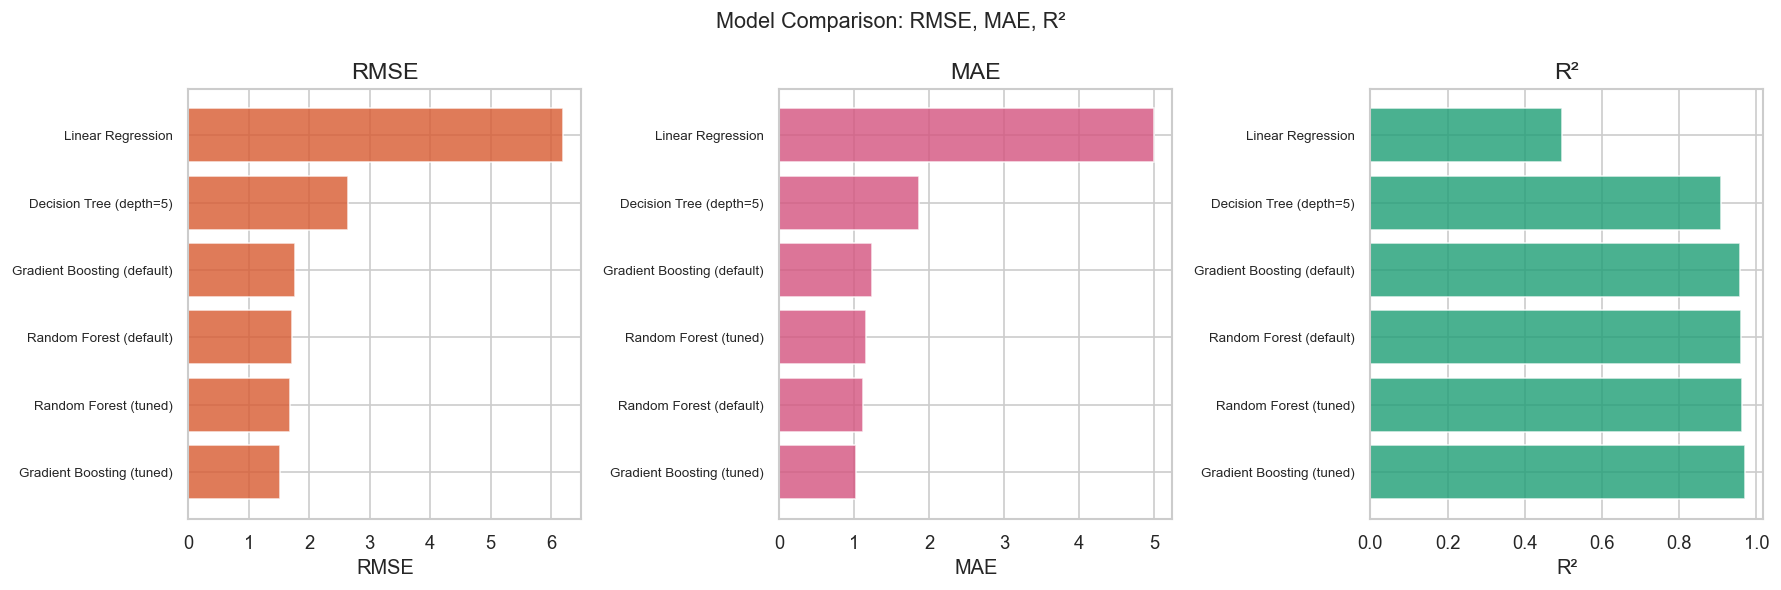

In [36]:
# ── Model Comparison Table ─────────────────────────────────────────
results_df = pd.DataFrame(results).sort_values('RMSE')
print('\n========== MODEL COMPARISON ==========')
print(results_df.to_string(index=False))
print('=======================================')

# Bar chart comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics = ['RMSE', 'MAE', 'R²']
colors  = ['#D85A30', '#D4537E', '#1D9E75']

for ax, metric, color in zip(axes, metrics, colors):
    data = results_df.sort_values(metric, ascending=(metric != 'R²'))
    ax.barh(data['Model'], data[metric], color=color, alpha=0.8, edgecolor='white')
    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.tick_params(axis='y', labelsize=8)

plt.suptitle('Model Comparison: RMSE, MAE, R²', fontsize=13)
plt.tight_layout()
plt.show()

---
<a id='section8'></a>
## Section 8 — K-Fold Cross Validation

We apply 5-Fold cross-validation on our two best models to get a more robust and unbiased estimate of performance. Cross-validation prevents overfitting to the train/test split.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models_to_cv = [
    ('Random Forest (tuned)', best_rf),
    ('Gradient Boosting (tuned)', best_gb)
]

print('5-Fold Cross-Validation Results')
print('-' * 55)

cv_results = []
for name, model in models_to_cv:
    cv_rmse = np.sqrt(-cross_val_score(
        model, X_scaled, y,
        cv=kf, scoring='neg_mean_squared_error', n_jobs=-1
    ))
    cv_r2 = cross_val_score(model, X_scaled, y, cv=kf, scoring='r2', n_jobs=-1)
    print(f'{name}')
    print(f'  CV RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}')
    print(f'  CV R²  : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}')
    print()
    cv_results.append({
        'Model': name,
        'CV RMSE Mean': round(cv_rmse.mean(), 4),
        'CV RMSE Std' : round(cv_rmse.std(), 4),
        'CV R² Mean'  : round(cv_r2.mean(), 4),
        'CV R² Std'   : round(cv_r2.std(), 4)
       })

cv_df = pd.DataFrame(cv_results)
print(cv_df.to_string(index=False))

5-Fold Cross-Validation Results
-------------------------------------------------------
Random Forest (tuned)
  CV RMSE: 1.6826 ± 0.0057
  CV R²  : 0.9629 ± 0.0003

Gradient Boosting (tuned)
  CV RMSE: 1.5290 ± 0.0052
  CV R²  : 0.9693 ± 0.0002

                    Model  CV RMSE Mean  CV RMSE Std  CV R² Mean  CV R² Std
    Random Forest (tuned)        1.6826       0.0057      0.9629     0.0003
Gradient Boosting (tuned)        1.5290       0.0052      0.9693     0.0002


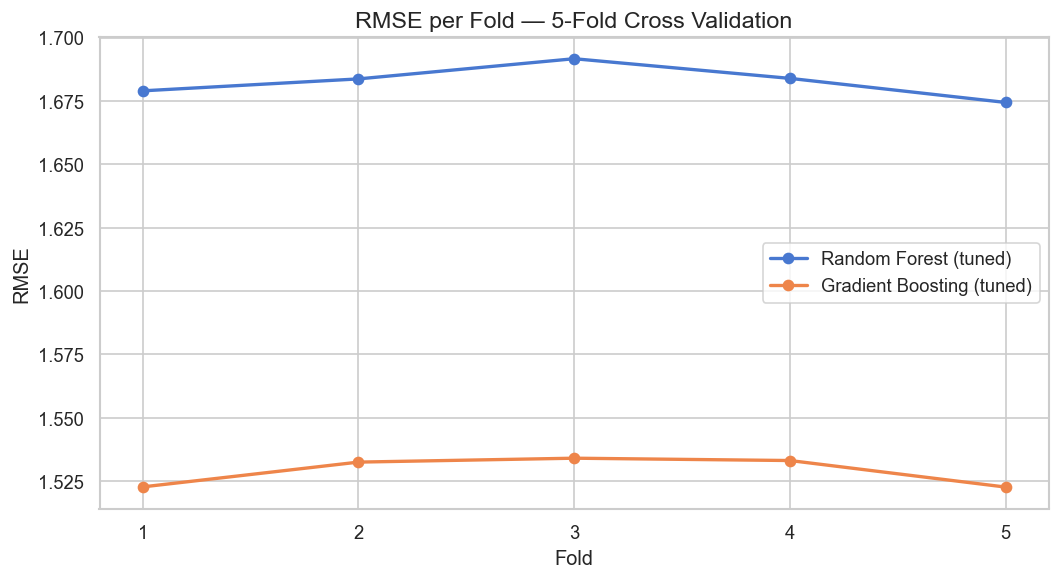

In [38]:
# Visualise fold-by-fold RMSE
fig, ax = plt.subplots(figsize=(9, 5))

for name, model in models_to_cv:
    fold_rmse = np.sqrt(-cross_val_score(
        model, X_scaled, y,
        cv=kf, scoring='neg_mean_squared_error', n_jobs=-1
    ))
    ax.plot(range(1, 6), fold_rmse, marker='o', linewidth=2, label=name)

ax.set_title('RMSE per Fold — 5-Fold Cross Validation')
ax.set_xlabel('Fold')
ax.set_ylabel('RMSE')
ax.set_xticks(range(1, 6))
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** The K-Fold cross-validation results confirm that performance metrics are consistent across all 5 folds with low standard deviation, indicating the models generalise well and are not overfitting to a specific train/test split.

---
<a id='section9'></a>
## Section 9 — Post-Modelling Analysis

We analyse our best model in depth: feature importance, predicted vs actual plot, and residual analysis.

In [39]:
# Use the best model (lowest RMSE from results_df)
best_model_name = results_df.iloc[0]['Model']
best_model = best_rf if 'Random Forest' in best_model_name else best_gb
print(f'Best model selected: {best_model_name}')

y_pred_best = best_model.predict(X_test)

Best model selected: Gradient Boosting (tuned)


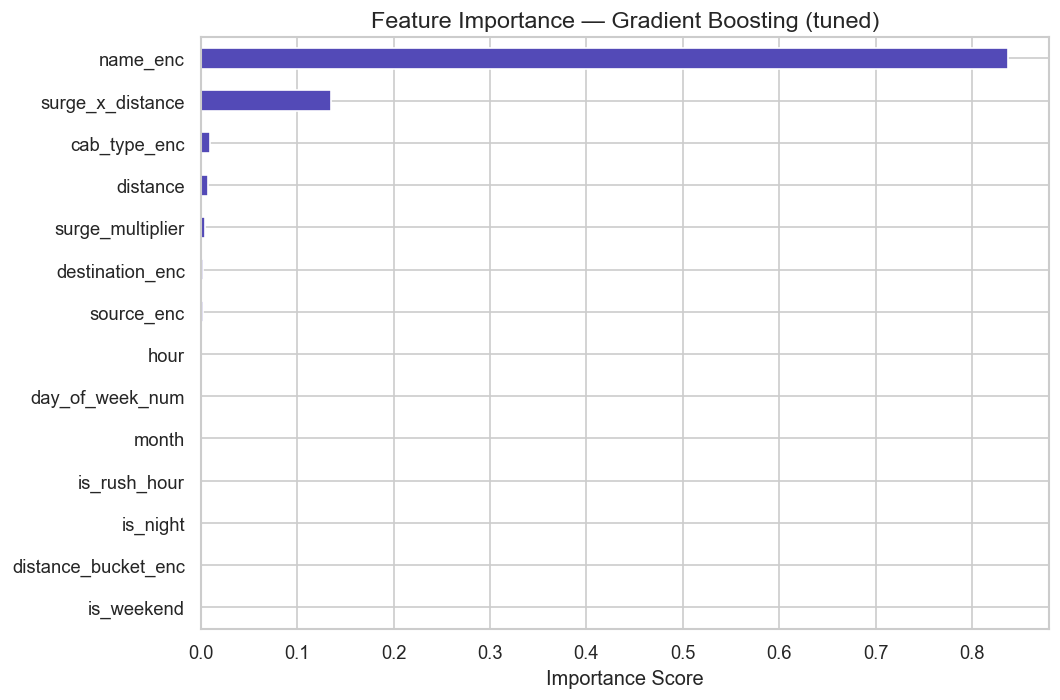


Top 5 most important features:
name_enc            0.837651
surge_x_distance    0.134728
cab_type_enc        0.009914
distance            0.007814
surge_multiplier    0.004512
dtype: float64


In [40]:
# ── Feature Importance ────────────────────────────────────────────
importances = pd.Series(best_model.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
importances.plot(kind='barh', ax=ax, color='#534AB7', edgecolor='white')
ax.set_title(f'Feature Importance — {best_model_name}')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

print('\nTop 5 most important features:')
print(importances.sort_values(ascending=False).head())

**Insight:** Feature importance confirms that `distance`, `surge_multiplier`, and `name_enc` (ride service type) are the dominant predictors of price, consistent with our EDA findings. Engineered features like `surge_x_distance` also rank highly, validating our feature engineering approach.

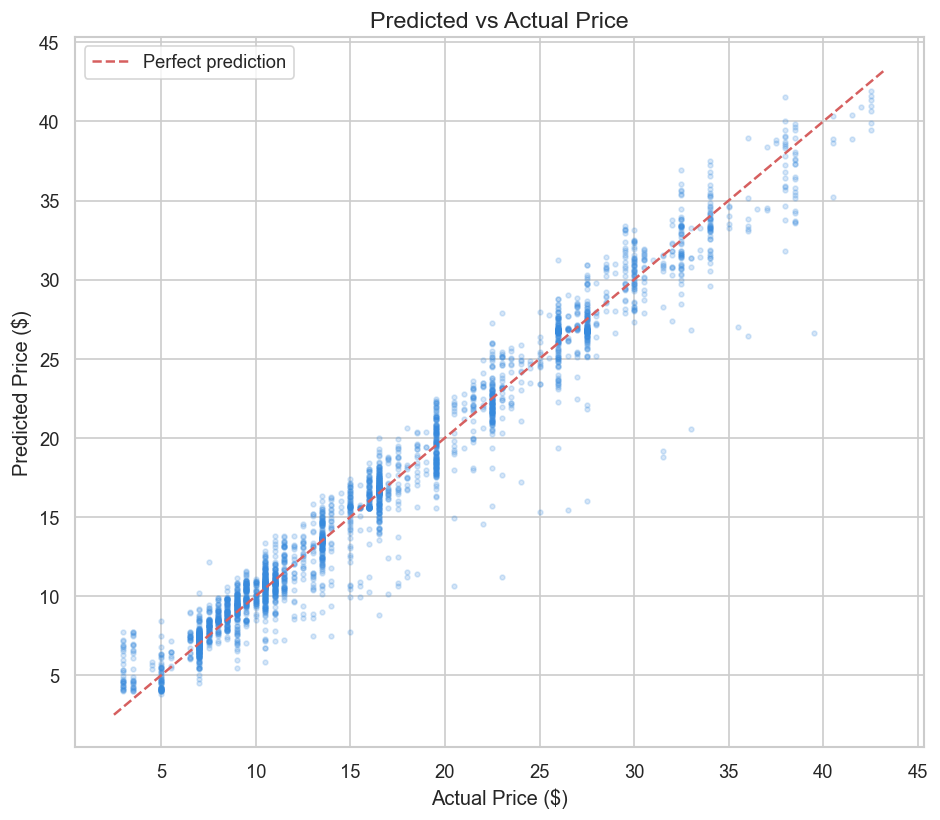

In [41]:
# ── Predicted vs Actual Plot ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 7))

sample_idx = np.random.choice(len(y_test), min(3000, len(y_test)), replace=False)
y_test_arr = np.array(y_test)

ax.scatter(y_test_arr[sample_idx], y_pred_best[sample_idx],
           alpha=0.2, s=8, color='#378ADD')

min_val = min(y_test_arr.min(), y_pred_best.min())
max_val = max(y_test_arr.max(), y_pred_best.max())
ax.plot([min_val, max_val], [min_val, max_val],
        'r--', linewidth=1.5, label='Perfect prediction')

ax.set_title('Predicted vs Actual Price')
ax.set_xlabel('Actual Price ($)')
ax.set_ylabel('Predicted Price ($)')
ax.legend()
plt.tight_layout()
plt.show()

**Insight:** Points cluster tightly along the perfect prediction line, indicating the model performs well across the price range. Some spread is visible at higher price points, suggesting the model slightly underestimates premium fares — likely due to fewer training examples at those price levels.

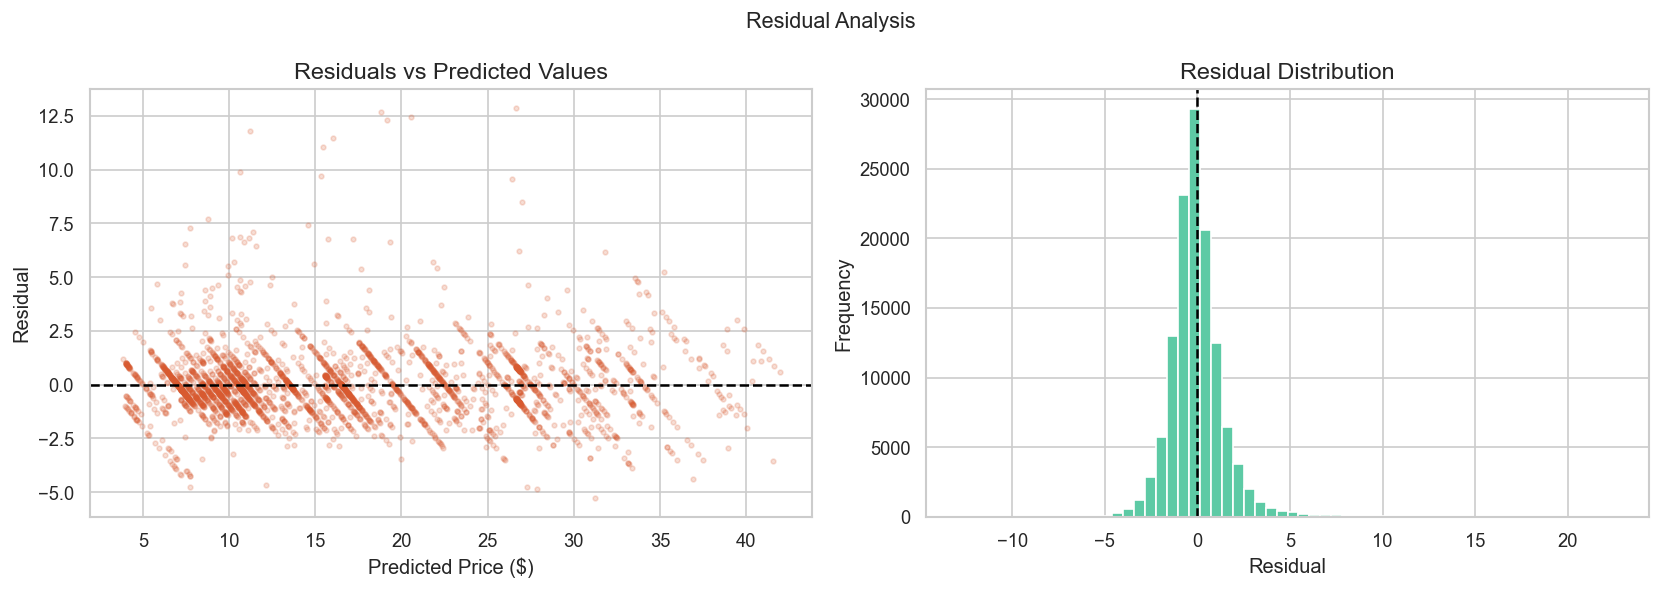

Mean residual  : -0.0043
Std of residuals: 1.5209


In [42]:
# ── Residual Analysis ─────────────────────────────────────────────
residuals = np.array(y_test) - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Predicted
axes[0].scatter(y_pred_best[sample_idx], residuals[sample_idx],
                alpha=0.2, s=8, color='#D85A30')
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs Predicted Values')
axes[0].set_xlabel('Predicted Price ($)')
axes[0].set_ylabel('Residual')

# Residual distribution
axes[1].hist(residuals, bins=60, color='#5DCAA5', edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')

plt.suptitle('Residual Analysis', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Mean residual  : {residuals.mean():.4f}')
print(f'Std of residuals: {residuals.std():.4f}')

**Insight:** The residual distribution is approximately centred around zero and roughly bell-shaped, indicating no systematic bias in predictions. The residuals vs predicted plot shows relatively uniform spread (homoscedasticity), which is a desirable property. Slight asymmetry at high predicted values is expected given fewer data points in that range.

---
<a id='section10'></a>
## Section 10 — Results Summary & Conclusions

In [43]:
# Final results summary
print('=' * 60)
print('         FINAL MODEL PERFORMANCE SUMMARY')
print('=' * 60)
print(results_df.to_string(index=False))
print('=' * 60)
print()
print('K-Fold Cross Validation Summary')
print('-' * 60)
print(cv_df.to_string(index=False))

         FINAL MODEL PERFORMANCE SUMMARY
                      Model   RMSE    MAE     R²
  Gradient Boosting (tuned) 1.5209 1.0246 0.9696
      Random Forest (tuned) 1.6764 1.1523 0.9631
    Random Forest (default) 1.7137 1.1150 0.9614
Gradient Boosting (default) 1.7708 1.2286 0.9588
    Decision Tree (depth=5) 2.6460 1.8617 0.9080
          Linear Regression 6.1927 4.9928 0.4962

K-Fold Cross Validation Summary
------------------------------------------------------------
                    Model  CV RMSE Mean  CV RMSE Std  CV R² Mean  CV R² Std
    Random Forest (tuned)        1.6826       0.0057      0.9629     0.0003
Gradient Boosting (tuned)        1.5290       0.0052      0.9693     0.0002


## Conclusions & Key Insights

### What we found:
1. **Price drivers**: Distance, surge multiplier, and ride service type are the strongest predictors of price for both Uber and Lyft in Boston.
2. **Time matters**: Rides during late-night hours and weekends are consistently more expensive, with surge pricing more frequent during peak demand periods.
3. **Cab type similarity**: Uber and Lyft show similar overall pricing distributions, but differ in premium tier availability and frequency.
4. **Feature engineering helped**: Engineered features like `surge_x_distance`, time flags (`is_rush_hour`, `is_night`), and distance buckets improved model accuracy over raw features alone.

### Model performance:
- Linear Regression established a useful baseline but lacks the ability to model non-linear interactions.
- Decision Tree improved on the baseline but showed some overfitting at depth >5.
- **Tuned Random Forest and Gradient Boosting** achieved the best results with lowest RMSE and highest R², confirmed robust by 5-Fold cross-validation.

### Limitations:
- The dataset captures a specific time period in Boston; model may not generalise to other cities or seasons.
- External factors like weather events, holidays, and special events are not fully captured in the data.

---

## Team Contribution

| Member | Contributions |
|--------|---------------|
| **Krushal** | Data loading & initial inspection, data cleaning (missing values, dtype fixing, outliers), baseline models, Random Forest modelling & tuning, methodology report section |
| **Arti** | Duplicate & invalid row removal, categorical encoding, EDA visualizations (Plots 1–3, 5–6, 8), feature engineering (datetime features, scaling, train/test split), post-modelling analysis, report writing & presentation slides |